# Final Corrective RAG (CRAG) Pipeline

![Corrective RAG Pipeline Infographic.png](<attachment:Corrective RAG Pipeline Infographic.png>)
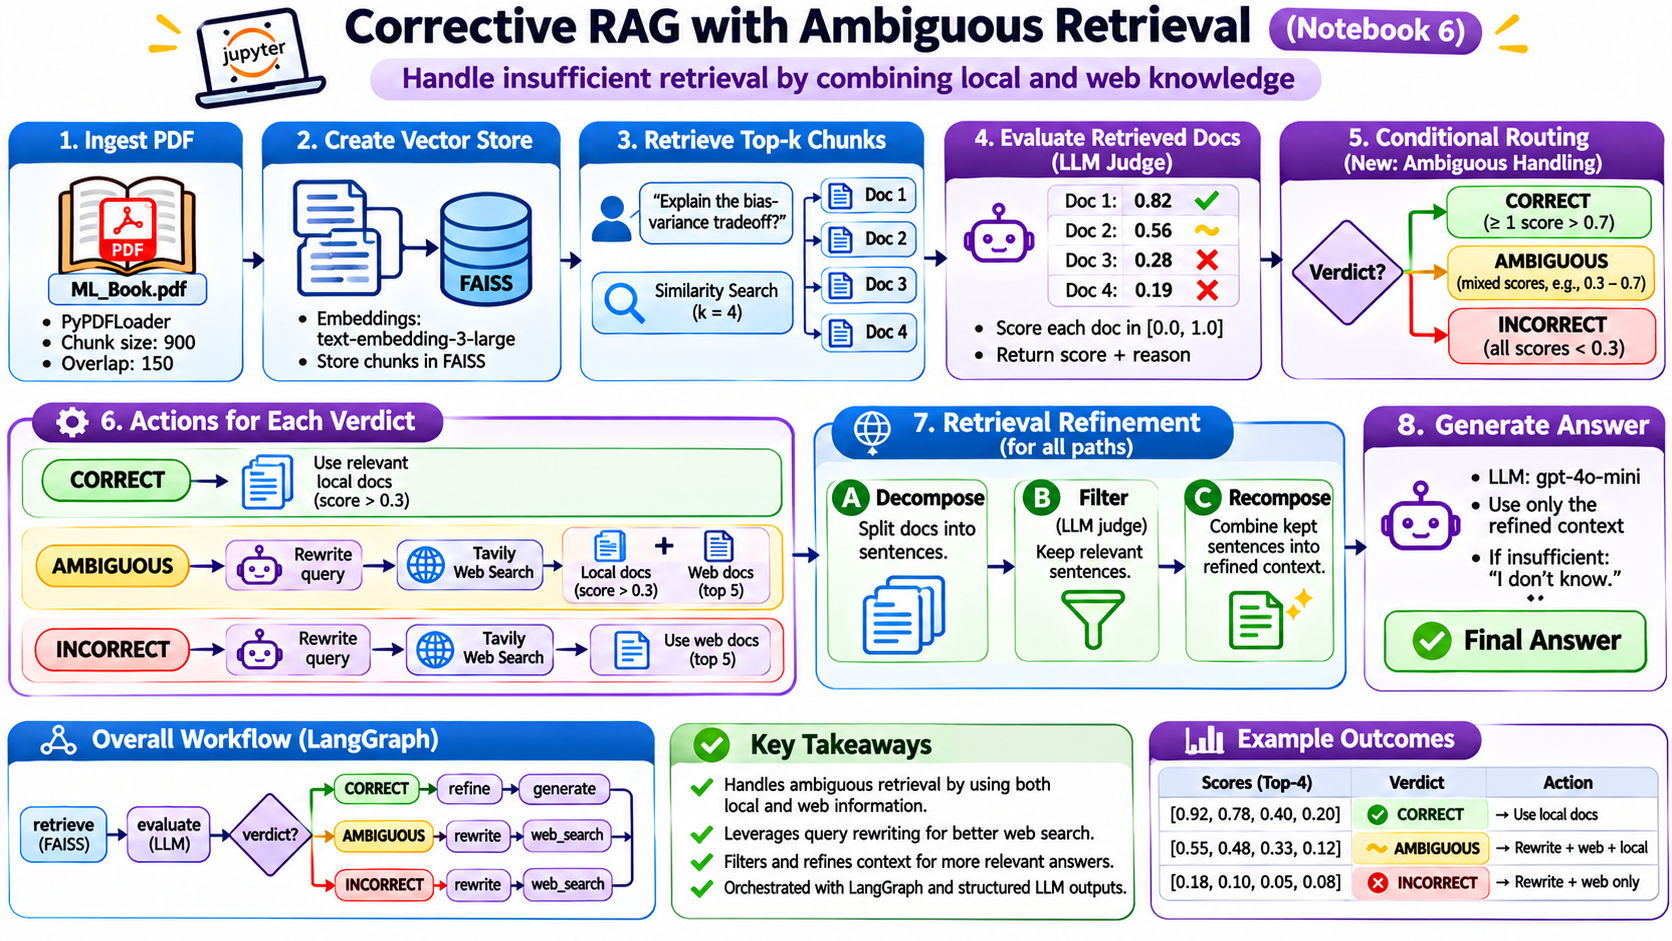


This notebook implements an advanced **Corrective RAG system using LangGraph, FAISS, GPT-4o-mini, and Tavily**. It evaluates retrieval quality, rewrites queries when necessary, and combines local and web knowledge to generate more reliable answers.

## 1. Workflow

```text
User Question
      ↓
FAISS Retrieval (Top-4 Chunks)
      ↓
LLM Document Evaluator
      ↓
Conditional Routing
      │
      ├── CORRECT → Local Documents
      │
      ├── INCORRECT → Query Rewrite → Web Search
      │
      └── AMBIGUOUS → Query Rewrite → Web Search
                                      + Local Documents
      ↓
Context Refinement
(Decompose → Filter → Recompose)
      ↓
LLM Answer Generation
      ↓
Final Answer
```

## 2. Main Components

| Component | Description |
|---|---|
| **FAISS** | Retrieves relevant PDF chunks using vector similarity. |
| **LLM Evaluator** | Assigns relevance scores between 0 and 1. |
| **Conditional Router** | Classifies retrieval as CORRECT, INCORRECT, or AMBIGUOUS. |
| **Query Rewriter** | Optimizes unsuccessful queries for web search. |
| **Tavily** | Retrieves external information when needed. |
| **Context Refinement** | Filters irrelevant sentences and recomposes useful evidence. |
| **LangGraph** | Orchestrates the complete workflow. |

## 3. Routing Rules

- **CORRECT:** Any document scores > 0.7 → use relevant local documents.
- **INCORRECT:** All documents score < 0.3 → rewrite query and retrieve web results.
- **AMBIGUOUS:** Otherwise → combine relevant local documents with web results.

## 4. Key Takeaway

**CRAG improves standard RAG by evaluating and correcting retrieval before answer generation.**

The system dynamically selects local knowledge, web knowledge, or both based on retrieval quality.

**Limitations:** LLM relevance judgments can be inaccurate, web sources are not independently verified, and additional LLM calls increase latency and API costs.

In [1]:
from typing import List, TypedDict, Literal
from pydantic import BaseModel
import re

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

from langchain_community.tools.tavily_search import TavilySearchResults
import os

# Load API credentials and other settings from the project .env file.
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

C:\Users\meisa\AppData\Local\Temp\ipykernel_41132\4220644883.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
W1102 15:06:08.444000 41132 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1102 15:06:08.486000 41132 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [2]:
docs = (
# Load the source PDF as page-level Document objects.
    PyPDFLoader("./documents/ML Book.pdf").load()
)

In [3]:
# Split pages into overlapping chunks so retrieval keeps local context.
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)
# Remove invalid UTF-8 bytes before embedding the text.
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")


In [4]:
#embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

from langchain_huggingface import HuggingFaceEmbeddings

hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, hf_embeddings)
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [5]:
# Shared model used for evaluation, query rewriting, filtering, and answers.
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [6]:
# A score above this threshold means local retrieval is sufficient.
UPPER_TH = 0.7
# Scores below this threshold indicate weak or irrelevant retrieval.
LOWER_TH = 0.3

In [7]:
# -----------------------------
# State
# -----------------------------
# Shared state passed between graph nodes; each node returns updates to it.
class State(TypedDict):
    question: str

    docs: List[Document]
    good_docs: List[Document]

    verdict: str
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str

    web_query: str
    
    web_docs: List[Document]

    answer: str

In [8]:
# -----------------------------
# Retrieve
# -----------------------------
def retrieve_node(state: State) -> State:
    q = state["question"]
# Retrieve matching chunks and store them in graph state.
    return {"docs": retriever.invoke(q)}


In [9]:
# -----------------------------
# Score-based doc evaluator
# -----------------------------
class DocEvalScore(BaseModel):
    score: float
    reason: str


doc_eval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only.",
        ),
        ("human", "Question: {question}\n\nChunk:\n{chunk}"),
    ]
)

# Ask the model for a validated relevance score and reason.
doc_eval_chain = doc_eval_prompt | llm.with_structured_output(DocEvalScore)


def eval_each_doc_node(state: State) -> State:
    q = state["question"]
    scores: List[float] = []
    good: List[Document] = []

# Score each retrieved chunk against the question.
    for d in state["docs"]:
        out = doc_eval_chain.invoke({"question": q, "chunk": d.page_content})
        scores.append(out.score)

        # Keep any doc above LOWER_TH as "weakly relevant"
        if out.score > LOWER_TH:
            good.append(d)

    # CORRECT: at least one doc > UPPER_TH
# One strongly relevant chunk is enough to trust local retrieval.
    if any(s > UPPER_TH for s in scores):
        return {
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }

    # INCORRECT: all docs < LOWER_TH
# Classify as incorrect only when results exist and every score is low.
    if len(scores) > 0 and all(s < LOWER_TH for s in scores):
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {LOWER_TH}.",
        }

    # AMBIGUOUS: otherwise
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}.",
    }


In [10]:
# -----------------------------
# Sentence-level DECOMPOSER
# -----------------------------
# Break combined context into sentence-sized units for fine filtering.
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]


# -----------------------------
# FILTER (LLM judge)
# -----------------------------
class KeepOrDrop(BaseModel):
    keep: bool


filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a relevance filter.\n"
            "Return keep=true if the sentence contains relevant information, news, or context related to the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

# Require a structured keep/drop decision for each sentence.
filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)


# -----------------------------
# Knowledge refinement
# (CORRECT => internal only)
# (INCORRECT => web only)
# (AMBIGUOUS => internal + web)
# -----------------------------
def refine(state: State) -> State:
    q = state["question"]

# Choose the evidence source based on the evaluator verdict.
    if state.get("verdict") == "CORRECT":
        docs_to_use = state["good_docs"]
    elif state.get("verdict") == "INCORRECT":
        docs_to_use = state["web_docs"]
    else:  # AMBIGUOUS
        docs_to_use = state["good_docs"] + state["web_docs"]

    context = "\n\n".join(d.page_content for d in docs_to_use).strip()

    strips = decompose_to_sentences(context)

    kept: List[str] = []
# Retain sentences judged directly useful to the question.
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

# Pass this cleaned evidence to answer generation.
    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }


In [11]:
# -----------------------------
# Query rewrite for web search
# -----------------------------
class WebQuery(BaseModel):
    query: str


rewrite_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Rewrite the user question into a web search query composed of keywords.\n"
            "Rules:\n"
            "- Keep it short (6–14 words).\n"
            "- If the question implies recency (e.g., recent/latest/last week/last month), add a constraint like (last 30 days).\n"
            "- Do NOT answer the question.\n"
            "- Return JSON with a single key: query",
        ),
        ("human", "Question: {question}"),
    ]
)

# Produce a concise search query in a predictable structured format.
rewrite_chain = rewrite_prompt | llm.with_structured_output(WebQuery)


def rewrite_query_node(state: State) -> State:
# Rewrite the original question before web search.
    out = rewrite_chain.invoke({"question": state["question"]})
    return {"web_query": out.query}


# -----------------------------
# Web search node: uses web_query
# -----------------------------
# Configure Tavily to return at most five web results.
tavily = TavilySearchResults(max_results=5)


def web_search_node(state: State) -> State:
# Use the rewritten query, falling back to the original question.
    q = state.get("web_query") or state["question"]
# Make the actual Tavily API search call.
    results = tavily.invoke({"query": q})

    web_docs: List[Document] = []
# Convert search hits into Documents for downstream refinement.
    for r in results or []:
        title = r.get("title", "")
        url = r.get("url", "")
        content = r.get("content", "") or r.get("snippet", "")
        text = f"TITLE: {title}\nURL: {url}\nCONTENT:\n{content}"
        web_docs.append(Document(page_content=text, metadata={"url": url, "title": title}))

    return {"web_docs": web_docs}


C:\Users\meisa\AppData\Local\Temp\ipykernel_41132\1332211969.py:37: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults(max_results=5)


In [12]:
# -----------------------------
# Generate
# -----------------------------
# Require the final answer to use refined evidence and admit when it is insufficient.
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'",
        ),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)


def generate(state: State) -> State:
# Generate an answer from the refined context.
    out = (answer_prompt | llm).invoke({"question": state["question"], "context": state["refined_context"]})
    return {"answer": out.content}


In [13]:
# -----------------------------
# Routing
# CORRECT => refine
# INCORRECT / AMBIGUOUS => rewrite -> web_search -> refine -> generate
# -----------------------------
# Strong local evidence skips web search; other verdicts rewrite then search.
def route_after_eval(state: State) -> str:
    if state["verdict"] == "CORRECT":
        return "refine"
    else:
        return "rewrite_query"


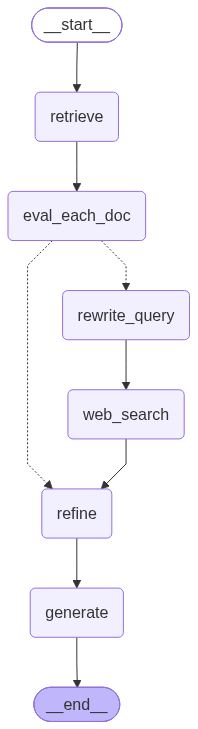

In [14]:
# -----------------------------
# Build graph
# -----------------------------
# Create the LangGraph workflow around the shared State schema.
g = StateGraph(State)

g.add_node("retrieve", retrieve_node)
g.add_node("eval_each_doc", eval_each_doc_node)

g.add_node("rewrite_query", rewrite_query_node)
g.add_node("web_search", web_search_node)

g.add_node("refine", refine)
g.add_node("generate", generate)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "eval_each_doc")

# Branch after evaluation based on the route label.
g.add_conditional_edges(
    "eval_each_doc",
    route_after_eval,
    {
        "refine": "refine",
        "rewrite_query": "rewrite_query",
    },
)

# non-correct path
# Non-correct verdicts rewrite the query, then call Tavily.
g.add_edge("rewrite_query", "web_search")
# Send web results through sentence-level refinement.
g.add_edge("web_search", "refine")

# correct path already goes to refine
g.add_edge("refine", "generate")
g.add_edge("generate", END)

# Compile the graph into an executable workflow.
app = g.compile()

app


In [16]:
# -----------------------------
# Run example
# -----------------------------
# Start the graph with the question and initialized state fields.
res = app.invoke(
    {
        "question": "Batch normalization vs layer normalization",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "web_query": "",
        "web_docs": [],
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
# Show the query sent to Tavily.
print("WEB_QUERY:", res["web_query"])
# Display the final answer returned by the graph.
print("\nOUTPUT:\n", res["answer"])


VERDICT: AMBIGUOUS
REASON: No chunk scored > 0.7, but not all were < 0.3.
WEB_QUERY: Batch normalization vs layer normalization

OUTPUT:
 Batch normalization normalizes over the examples in a mini-batch, while layer normalization normalizes across the features for each individual example. Batch normalization is generally more effective for feedforward neural networks and convolutional neural networks (CNNs), whereas layer normalization is better suited for recurrent neural networks (RNNs) and models with variable input lengths. Additionally, batch normalization's dependency on batch statistics can lead to complications with small batch sizes, while layer normalization is independent of batch size, offering consistent performance regardless of batch configurations.
